In [1]:
import numpy as np
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
y="""-1.85942
-1.85576
-1.85201
-1.84817
-1.84424
-1.84022
-1.8361
-1.83189
-1.82759
-1.8232
-1.81872
-1.81415
-1.80948
-1.80472
-1.79987
-1.79491
-1.78985
-1.78469
-1.77941
-1.77403
-1.76854
-1.76294
-1.75724
-1.75145
-1.74557
-1.73961
-1.73358
-1.72749
-1.72134
-1.71515
-1.70891
-1.70263
-1.6963
-1.68992
-1.68349
-1.67699
-1.67041
-1.66374
-1.65695
-1.65002
-1.64292
-1.6356
-1.628
-1.62003
-1.61159
-1.60254
-1.59273
-1.58195
-1.57001
-1.55668
-1.54181
-1.52529
-1.50715
-1.48758
-1.46691
-1.44564
-1.42432
-1.40345
-1.38348
-1.36466
-1.34713
-1.33089
-1.31587
-1.30195
-1.28898
-1.27684
-1.2654
-1.25455
-1.24419
-1.23426
-1.22468
-1.21539
-1.20635
-1.19751
-1.18884
-1.18029
-1.17186
-1.1635
-1.15522
-1.147
-1.13884
-1.13074
-1.12272
-1.11479
-1.10695
-1.09924
-1.09168
-1.08428
-1.07707
-1.07006
-1.06327
-1.0567
-1.05038
-1.04429
-1.03845
-1.03284
-1.02747
-1.02232
-1.01739
-1.01267"""
y=[float(i) for i in y.splitlines()]

<Axes: >

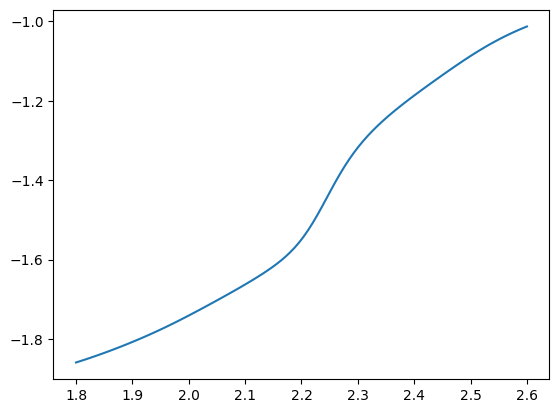

In [6]:
x = np.linspace(1.8,2.6, 100)
sns.lineplot(x=x,y=y)

In [78]:
def parallel_tempering(matrix: np.ndarray, beta0: float, beta1: float,tau:int = 20,sweeps:int = 1000,  init_state: np.ndarray = None):
    N = matrix.shape[0]
    print(N)
    step = (beta1 - beta0) / (sweeps - 1)
    beta = beta0
    energy = lambda state: ( state.transpose() @ matrix @ state ) / 2
    if init_state is None:
        state = np.random.choice([-1,1], N, replace=True)
    else:
        state = init_state
    ene = energy(state)
    ene_vals = []
    ene_vals.append(ene)
    best_ene = ene
    best_state = state
    for i in range(sweeps):
        for s in range(N):
            rng = np.random.sample()
            state[s] = -1 * state[s]
            trial_ene = energy(state)
            if np.log(rng) < (beta * (ene - trial_ene)):
                ene =  trial_ene
                ene_vals.append(ene)
                if ene < best_ene:
                    best_ene = ene
                    best_state = state
            else:
                state[s] = -1 * state[s]
        beta += step
    return best_ene, best_state, ene_vals

In [67]:
def gset_to_array(path: str):
    with open(path) as gfile:
        nodes, edges = [int(i) for i in gfile.readline().strip().split()]
        arr = np.zeros((nodes, nodes))
        for line in gfile.readlines():
            args = line.strip().split()
            if len(args) < 2:
                continue
            if len(args) == 2:
                arr[int(args[0]), int(args[1])] = 1
                arr[int(args[1]), int(args[0])] = 1
                continue

            arr[int(args[0]), int(args[1])] = float(args[2])
            arr[int(args[1]), int(args[0])] = float(args[2])
    return arr

In [70]:
J = gset_to_array(os.environ['GSET'] + '/sk/sk_normal_n_200_0.gset')

In [59]:
J = np.random.standard_normal(size=200*200).reshape((200,200))

In [71]:
ene, state, vals = parallel_tempering(-J, 0.05, 2)

200


1081.6601840158783

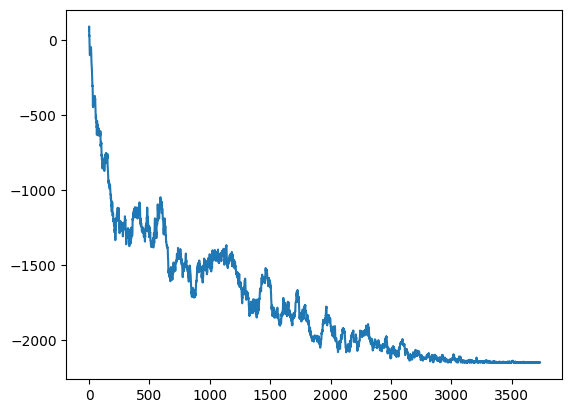

In [77]:
sns.lineplot(vals)
cut = (-ene + J.sum()) / 2
cut

1081.6601840158783

In [66]:
ene

-1533.4875927464097

In [48]:
J.sum()

11.987652830127235